# Data cleaning and base dataset

This notebook cleans the SAIL 2025 sensor data, selects 3 sensors and combines them with the sensor locations and the weather data. The result is one base dataset that we use in the project report: `data/processed/basisdataset.csv`.

Author: Fabian

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

## 1. Load the data

In [2]:
df_flow = pd.read_csv("../data/raw/sensordata_SAIL2025.csv")
df_loc = pd.read_csv("../data/raw/sensor_locations.csv")
df_weather = pd.read_csv("../data/raw/SAIL_Amsterdam_Weather_Data.csv")

df_flow["timestamp"] = pd.to_datetime(df_flow["timestamp"])

print(df_flow.shape)
print(df_flow["timestamp"].min(), "tot", df_flow["timestamp"].max())

(2400, 81)
2025-08-20 00:00:00+02:00 tot 2025-08-24 23:57:00+02:00


## 2. Check the data quality

In [3]:
# lege waardes, dubbele tijden en gaten in de tijd
print("lege waardes:", df_flow.isna().sum().sum())
print("dubbele tijden:", df_flow["timestamp"].duplicated().sum())

stappen = df_flow["timestamp"].diff().dropna()
print("gaten in de tijd:", (stappen != pd.Timedelta("3min")).sum())

lege waardes: 0
dubbele tijden: 0
gaten in de tijd: 0


In [4]:
# per sensor-kolom: hoeveel procent van de tijd staat hij op 0?
time_cols = ["timestamp", "hour", "minute", "day", "month", "weekday", "is_weekend"]
sensor_cols = []
for col in df_flow.columns:
    if col not in time_cols:
        sensor_cols.append(col)

zeros = {}
for col in sensor_cols:
    zeros[col] = round((df_flow[col] == 0).mean() * 100)

print(pd.Series(zeros).sort_values(ascending=False).head(15))

GASA-06_95       100
GASA-06_275      100
GVCV-09_260       99
GVCV-09_80        99
GVCV-08_225       81
GVCV-07_230       79
GVCV-07_50        79
GVCV-08_45        78
GVCV-06_95        75
GVCV-06_275       74
GASA-06-B_275     68
GASA-06-B_95      68
GVCV-05-A_155     61
GVCV-05-B_210     60
GVCV-01_220       59
dtype: int64


What we see:
- There are no empty values and no gaps in time, every row is exactly 3 minutes after the previous one.
- Some sensors are (almost) always 0: `GASA-06` and `GVCV-09`. These sensors did not work.
- `CMSA-GAWW-20` stops working on 23 August at 20:15.
- The ferry sensors (`GVCV`) are often 0. This is normal, people only pass when a ferry arrives.
- All `GASA` sensors are 0 until 20 August 08:09. They were switched on when SAIL started, so these zeros are not real measurements.

## 3. Select 3 sensors

| Sensor | Location | Why |
|---|---|---|
| GASA-03 | Oosterdoksbrug | Busiest sensor, on the main SAIL route |
| GASA-04 | CS towards Oosterdokskade | Visitors coming out of Central Station |
| GACM-04 | Damrak 1-5 | City centre, used to compare with the event area |

Together they follow a visitor from the station, to the event area, with the city centre as reference.

In [5]:
sensors = ["GASA-03", "GASA-04", "GACM-04"]

# elke sensor meet 2 looprichtingen, die tellen we op
df_base = df_flow[time_cols].copy()

for sensor in sensors:
    directions = []
    for col in sensor_cols:
        if col.startswith(sensor + "_"):
            directions.append(col)
    print(sensor, directions)
    df_base[sensor] = df_flow[directions].sum(axis=1)

df_base.head()

GASA-03 ['GASA-03_105', 'GASA-03_285']
GASA-04 ['GASA-04_135', 'GASA-04_315']
GACM-04 ['GACM-04_50', 'GACM-04_230']


,timestamp,hour,minute,day,month,weekday,is_weekend,GASA-03,GASA-04,GACM-04
0,2025-08-20 00:00:00+02:00,0,0,20,8,2,0,0,0,28
1,2025-08-20 00:03:00+02:00,0,3,20,8,2,0,0,0,18
2,2025-08-20 00:06:00+02:00,0,6,20,8,2,0,0,0,22
3,2025-08-20 00:09:00+02:00,0,9,20,8,2,0,0,0,47
4,2025-08-20 00:12:00+02:00,0,12,20,8,2,0,0,0,40


## 4. Clean the selected sensors

In [6]:
def zeros_before_start(df, column):
    # alle nullen voordat de sensor voor het eerst iets meet worden leeg (NaN)
    if (df[column] > 0).sum() == 0:
        return None
    first = df[df[column] > 0].index[0]
    if first > 0:
        df.loc[:first - 1, column] = None
    return first


for sensor in sensors:
    first = zeros_before_start(df_base, sensor)
    print(sensor, "meet vanaf", df_base.loc[first, "timestamp"])

GASA-03 meet vanaf 2025-08-20 08:12:00+02:00
GASA-04 meet vanaf 2025-08-20 08:12:00+02:00
GACM-04 meet vanaf 2025-08-20 00:00:00+02:00


In [7]:
# negatieve waardes of rare uitschieters?
for sensor in sensors:
    print(sensor, "min:", df_base[sensor].min(), "max:", df_base[sensor].max(), "leeg:", df_base[sensor].isna().sum())

GASA-03 min: 0.0 max: 775.0 leeg: 164
GASA-04 min: 0.0 max: 534.0 leeg: 164
GACM-04 min: 0 max: 448 leeg: 0


No negative values. The maximum values are high but realistic for SAIL (both directions together, per 3 minutes), so we keep them.

## 5. Add the sensor locations

In [8]:
df_loc = df_loc[df_loc["Objectnummer"].isin(sensors)].copy()

# Lat/Long staat in 1 kolom, en de breedtes gebruiken een komma als decimaal
lat = []
lon = []
for i in df_loc["Lat/Long"]:
    parts = i.split(",")
    lat.append(float(parts[0]))
    lon.append(float(parts[1]))

df_loc["lat"] = lat
df_loc["lon"] = lon
df_loc["width_m"] = df_loc["Effectieve breedte"].astype(str).str.replace(",", ".").astype(float)

df_loc = df_loc.rename(columns={"Objectnummer": "sensor", "Locatienaam": "location"})
df_loc = df_loc[["sensor", "location", "lat", "lon", "width_m"]]
df_loc

,sensor,location,lat,lon,width_m
12,GACM-04,Damrak 1-5,52.377027,4.898059,6.2
32,GASA-03,Oosterdoksbrug,52.377620,4.911010,8.0
33,GASA-04,CSriOosterdokskade,52.377020,4.903520,7.0


## 6. Make the base dataset (long format)

We put the 3 sensors under each other, so every row is one sensor at one moment. This makes it easy to merge the locations and to make plots per sensor.

In [9]:
parts = []
for sensor in sensors:
    part = df_base[time_cols].copy()
    part["sensor"] = sensor
    part["flow"] = df_base[sensor]
    parts.append(part)

df_long = pd.concat(parts, ignore_index=True)
df_long = df_long.merge(df_loc, on="sensor", how="left")

# mensen per meter breedte, zo kun je smalle en brede plekken eerlijk vergelijken
df_long["flow_per_m"] = round(df_long["flow"] / df_long["width_m"], 2)

df_long.head()

,timestamp,hour,minute,day,month,weekday,is_weekend,sensor,flow,location,lat,lon,width_m,flow_per_m
0,2025-08-20 00:00:00+02:00,0,0,20,8,2,0,GASA-03,NaN,Oosterdoksbrug,52.37762,4.91101,8.0,NaN
1,2025-08-20 00:03:00+02:00,0,3,20,8,2,0,GASA-03,NaN,Oosterdoksbrug,52.37762,4.91101,8.0,NaN
2,2025-08-20 00:06:00+02:00,0,6,20,8,2,0,GASA-03,NaN,Oosterdoksbrug,52.37762,4.91101,8.0,NaN
3,2025-08-20 00:09:00+02:00,0,9,20,8,2,0,GASA-03,NaN,Oosterdoksbrug,52.37762,4.91101,8.0,NaN
4,2025-08-20 00:12:00+02:00,0,12,20,8,2,0,GASA-03,NaN,Oosterdoksbrug,52.37762,4.91101,8.0,NaN


## 7. Add the weather data

In [10]:
# laatste regel van het weerbestand is kapot, die valt weg
df_weather["DateTime"] = pd.to_datetime(df_weather["DateTime"], format="%Y%m%d %H:%M", errors="coerce")
df_weather = df_weather.dropna()
df_weather = df_weather.rename(columns={
    "DateTime": "weather_time",
    "Temperature_°C": "temperature",
    "Humidity_%": "humidity",
    "Rain_mm": "rain_mm",
})

print(df_weather["weather_time"].min(), "tot", df_weather["weather_time"].max())

2025-08-20 02:00:00 tot 2025-08-22 18:30:00


In [11]:
# weer is per 10 minuten, sensoren per 3 minuten: we koppelen op het 10-minuten blok
df_long["weather_time"] = df_long["timestamp"].dt.tz_localize(None).dt.floor("10min")
df_long = df_long.merge(df_weather, on="weather_time", how="left")
df_long = df_long.drop(columns="weather_time")

print("rijen zonder weer:", df_long["temperature"].isna().sum(), "van de", len(df_long))

rijen zonder weer: 3318 van de 7200


**Note:** the weather file only runs until 22 August 18:30, so the weather columns are empty after that moment. We assume the weather times are in local time (same as the sensor data).

## 8. Check and save

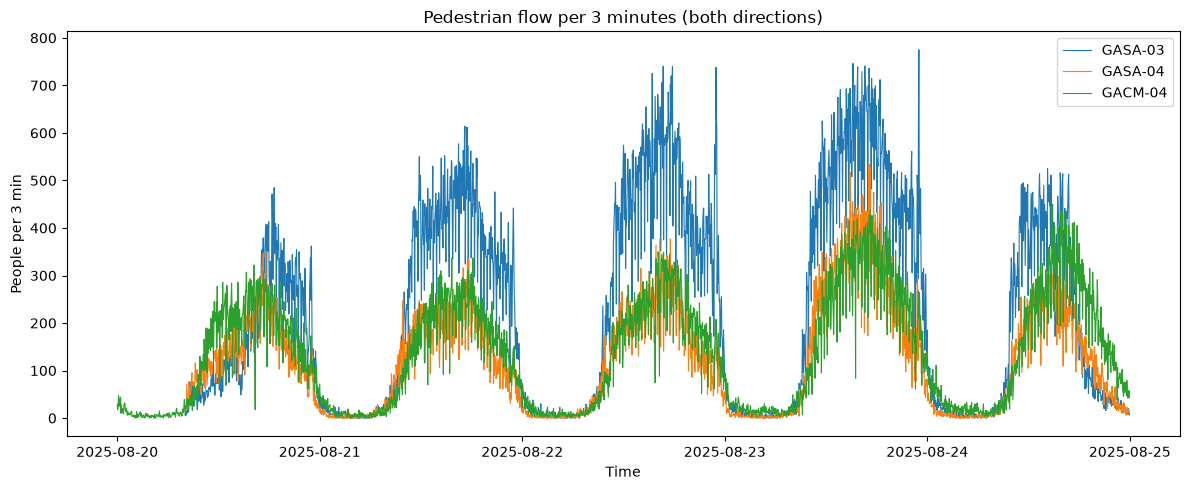

In [12]:
fig, ax = plt.subplots(figsize=(12, 5))
for sensor in sensors:
    data = df_long[df_long["sensor"] == sensor]
    ax.plot(data["timestamp"], data["flow"], label=sensor, linewidth=0.8)

ax.set_title("Pedestrian flow per 3 minutes (both directions)")
ax.set_xlabel("Time")
ax.set_ylabel("People per 3 min")
ax.legend()
plt.tight_layout()
plt.savefig("../figures/flow_3_sensors.png", dpi=150)
plt.show()

In [13]:
df_long.to_csv("../data/processed/basisdataset.csv", index=False)
print(df_long.shape)
print(df_long.columns.tolist())

(7200, 17)
['timestamp', 'hour', 'minute', 'day', 'month', 'weekday', 'is_weekend', 'sensor', 'flow', 'location', 'lat', 'lon', 'width_m', 'flow_per_m', 'temperature', 'humidity', 'rain_mm']
